# Used Car Price Prediction Using Machine Learning

**ML Type:** Regression (Linear Regression)

## Program

### Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Upload Dataset File

In [2]:
# Only needed in Google Colab (skip if 'car data.csv' is in the same folder)
# from google.colab import files
# uploaded = files.upload()

### Load the Dataset

In [3]:
df = pd.read_csv("car data.csv")
print("Used Car Dataset Shape:", df.shape)
df.head()

Used Car Dataset Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


### Check Dataset Information

In [4]:
print(df.columns)
print("Missing Values:")
print(df.isnull().sum())

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
      dtype='str')
Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


### Statistical Summary of the Dataset

In [5]:
df.describe().round(2)

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.00,301.00,301.00,301.00,301.00
mean,2013.63,4.66,7.63,36947.21,0.04
std,2.89,5.08,8.64,38886.88,0.25
min,2003.00,0.10,0.32,500.00,0.00
25%,2012.00,0.90,1.20,15000.00,0.00
50%,2014.00,3.60,6.40,32000.00,0.00
75%,2016.00,6.00,9.90,48767.00,0.00
max,2018.00,35.00,92.60,500000.00,3.00


### Remove Unnecessary Columns

In [6]:
df = df.drop("Car_Name", axis=1)
df = df.dropna()
df.head()

,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


### Create Car Age Feature

In [7]:
df["Car_Age"] = 2026 - df["Year"]
df = df.drop("Year", axis=1)
df.head()

,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


### Convert Categorical Data into Numerical Data

In [8]:
df = pd.get_dummies(df, drop_first=True, dtype=int)
print("Dataset Shape After Encoding:", df.shape)
df.head()

Dataset Shape After Encoding: (301, 9)


,Selling_Price,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual
0,3.35,5.59,27000,0,12,0,1,0,1
1,4.75,9.54,43000,0,13,1,0,0,1
2,7.25,9.85,6900,0,9,0,1,0,1
3,2.85,4.15,5200,0,15,0,1,0,1
4,4.60,6.87,42450,0,12,1,0,0,1


### Check Selling Price Summary

In [9]:
print(df["Selling_Price"].describe())

count    301.000000
mean       4.661296
std        5.082812
min        0.100000
25%        0.900000
50%        3.600000
75%        6.000000
max       35.000000
Name: Selling_Price, dtype: float64


### Visualize Dataset

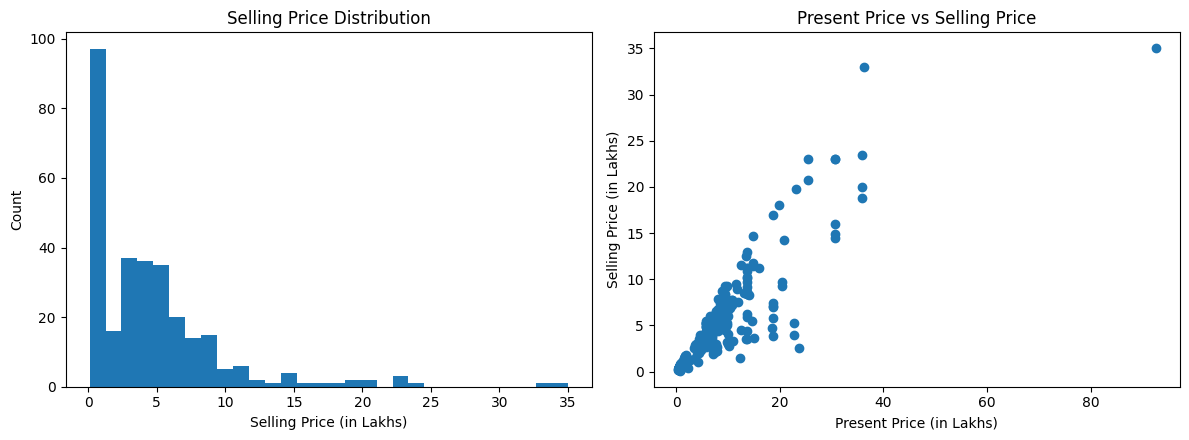

In [10]:
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.hist(df["Selling_Price"], bins=30)
plt.xlabel("Selling Price (in Lakhs)")
plt.ylabel("Count")
plt.title("Selling Price Distribution")

plt.subplot(1, 2, 2)
plt.scatter(df["Present_Price"], df["Selling_Price"])
plt.xlabel("Present Price (in Lakhs)")
plt.ylabel("Selling Price (in Lakhs)")
plt.title("Present Price vs Selling Price")

plt.tight_layout()
plt.show()

### Split Input and Output

In [11]:
X = df.drop("Selling_Price", axis=1)
y = df["Selling_Price"]

### Train-Test Split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (240, 8)
Testing Data: (61, 8)


### Train Linear Regression Model

In [13]:
model = LinearRegression()
model.fit(
    X_train,
    y_train
)
print("Model Training Completed!")

Model Training Completed!


### Make Predictions

In [14]:
y_pred = model.predict(X_test)
print(y_pred[:10].round(2))

[ 2.96  8.18  6.45 -1.42  9.09  7.42  1.34  0.84  1.37  7.49]


### Calculate Evaluation Metrics

In [15]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R2 Score:", round(r2, 4))
print("Model Accuracy (R2 x 100):", round(r2 * 100, 2), "%")

Mean Absolute Error (MAE): 1.2162
Mean Squared Error (MSE): 3.4788
Root Mean Squared Error (RMSE): 1.8652
R2 Score: 0.849
Model Accuracy (R2 x 100): 84.9 %


### Actual vs Predicted Prices

In [16]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred.round(2)
})
comparison.head()

,Actual Price,Predicted Price
0,0.35,2.96
1,10.11,8.18
2,4.95,6.45
3,0.15,-1.42
4,6.95,9.09


### Actual vs Predicted Graph

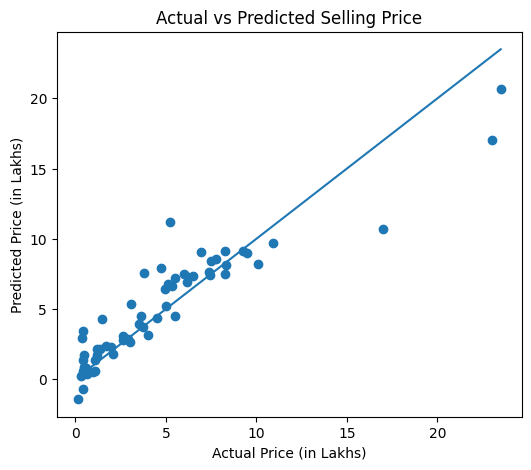

In [17]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()])
plt.xlabel("Actual Price (in Lakhs)")
plt.ylabel("Predicted Price (in Lakhs)")
plt.title("Actual vs Predicted Selling Price")
plt.show()

### Feature Coefficients

In [18]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_.round(6)
})
coefficients

,Feature,Coefficient
0,Present_Price,0.429153
1,Kms_Driven,-0.000006
2,Owner,-0.903760
3,Car_Age,-0.353801
4,Fuel_Type_Diesel,2.533273
5,Fuel_Type_Petrol,0.738464
6,Seller_Type_Individual,-1.190593
7,Transmission_Manual,-1.639022


### Predict Price of a New Car

In [19]:
def predict_car_price(present_price, kms_driven, owner, car_age,
                      fuel_type, seller_type, transmission):
    input_data = pd.DataFrame([{
        "Present_Price": present_price,
        "Kms_Driven": kms_driven,
        "Owner": owner,
        "Car_Age": car_age,
        "Fuel_Type_Diesel": 1 if fuel_type == "Diesel" else 0,
        "Fuel_Type_Petrol": 1 if fuel_type == "Petrol" else 0,
        "Seller_Type_Individual": 1 if seller_type == "Individual" else 0,
        "Transmission_Manual": 1 if transmission == "Manual" else 0
    }])
    input_data = input_data[X.columns]
    price = model.predict(input_data)
    return round(price[0], 2)

result = predict_car_price(
    present_price=9.85,
    kms_driven=45000,
    owner=0,
    car_age=8,
    fuel_type="Petrol",
    seller_type="Dealer",
    transmission="Manual"
)
print("Predicted Selling Price:", result, "Lakhs")

Predicted Selling Price: 7.07 Lakhs
